# Problem 1 - Smart Home Energy Consumption using Bayesian Networks

**Group members:**

| Name | Roll No |
|---|---|
| | |
| | |
| | |
| | |
| | |

**Course:** Artificial Intelligence

## 1. Setup

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator

SEED = 42
SIZES = [500, 5000, 20000]

# Part A - Expert Bayesian Network

## 2. Network structure

In [2]:
# W = Weather, D = DayType, O = Occupancy, A = AC usage, L = Appliance load, E = Energy consumption
edges = [("D", "O"), ("W", "A"), ("O", "A"), ("O", "L"), ("A", "E"), ("L", "E")]

states = {
    "W": ["Hot", "Mild", "Cold"],
    "D": ["Weekday", "Weekend"],
    "O": ["High", "Low"],
    "A": ["On", "Off"],
    "L": ["Heavy", "Light"],
    "E": ["High", "Low"],
}

full_name = {"W": "Weather", "D": "DayType", "O": "Occupancy",
             "A": "AC_Usage", "L": "ApplianceLoad", "E": "EnergyConsumption"}

expert = DiscreteBayesianNetwork(edges)

## 3. Conditional probability tables

In [3]:
cpd_W = TabularCPD("W", 3, [[0.50], [0.30], [0.20]], state_names={"W": states["W"]})
cpd_D = TabularCPD("D", 2, [[0.70], [0.30]], state_names={"D": states["D"]})

# columns are Weekday, Weekend
cpd_O = TabularCPD("O", 2, [[0.45, 0.80],
                            [0.55, 0.20]],
                   evidence=["D"], evidence_card=[2],
                   state_names={"O": states["O"], "D": states["D"]})

# columns go (Hot,High) (Hot,Low) (Mild,High) (Mild,Low) (Cold,High) (Cold,Low)
ac_on = [0.90, 0.60, 0.40, 0.15, 0.10, 0.05]
cpd_A = TabularCPD("A", 2, [ac_on, [1 - p for p in ac_on]],
                   evidence=["W", "O"], evidence_card=[3, 2],
                   state_names={"A": states["A"], "W": states["W"], "O": states["O"]})

cpd_L = TabularCPD("L", 2, [[0.75, 0.35],
                            [0.25, 0.65]],
                   evidence=["O"], evidence_card=[2],
                   state_names={"L": states["L"], "O": states["O"]})

# columns go (On,Heavy) (On,Light) (Off,Heavy) (Off,Light)
e_high = [0.92, 0.68, 0.55, 0.12]
cpd_E = TabularCPD("E", 2, [e_high, [1 - p for p in e_high]],
                   evidence=["A", "L"], evidence_card=[2, 2],
                   state_names={"E": states["E"], "A": states["A"], "L": states["L"]})

expert.add_cpds(cpd_W, cpd_D, cpd_O, cpd_A, cpd_L, cpd_E)

for cpd in expert.get_cpds():
    print(cpd, "\n")

+---------+-----+
| W(Hot)  | 0.5 |
+---------+-----+
| W(Mild) | 0.3 |
+---------+-----+
| W(Cold) | 0.2 |
+---------+-----+ 

+------------+-----+
| D(Weekday) | 0.7 |
+------------+-----+
| D(Weekend) | 0.3 |
+------------+-----+ 

+---------+------------+------------+
| D       | D(Weekday) | D(Weekend) |
+---------+------------+------------+
| O(High) | 0.45       | 0.8        |
+---------+------------+------------+
| O(Low)  | 0.55       | 0.2        |
+---------+------------+------------+ 

+--------+---------------------+-----+---------+---------+---------+
| W      | W(Hot)              | ... | W(Mild) | W(Cold) | W(Cold) |
+--------+---------------------+-----+---------+---------+---------+
| O      | O(High)             | ... | O(Low)  | O(High) | O(Low)  |
+--------+---------------------+-----+---------+---------+---------+
| A(On)  | 0.9                 | ... | 0.15    | 0.1     | 0.05    |
+--------+---------------------+-----+---------+---------+---------+
| A(Off) | 0.0

## 4. Checking that every CPT column sums to 1

In [4]:
all_ok = True
for cpd in expert.get_cpds():
    table = cpd.get_values()          # rows = states of the variable, columns = parent configs
    col_sums = table.sum(axis=0)
    ok = np.allclose(col_sums, 1.0)
    all_ok = all_ok and ok
    print(f"{full_name[cpd.variable]:<18} columns: {len(col_sums)}  sums: {np.round(col_sums, 6)}  ok: {ok}")

print("\nAll CPTs valid:", all_ok)
print("pgmpy check_model():", expert.check_model())

Weather            columns: 1  sums: [1.]  ok: True
DayType            columns: 1  sums: [1.]  ok: True
Occupancy          columns: 2  sums: [1. 1.]  ok: True
AC_Usage           columns: 6  sums: [1. 1. 1. 1. 1. 1.]  ok: True
ApplianceLoad      columns: 2  sums: [1. 1.]  ok: True
EnergyConsumption  columns: 4  sums: [1. 1. 1. 1.]  ok: True

All CPTs valid: True
pgmpy check_model(): True


## 5. Visualising the network

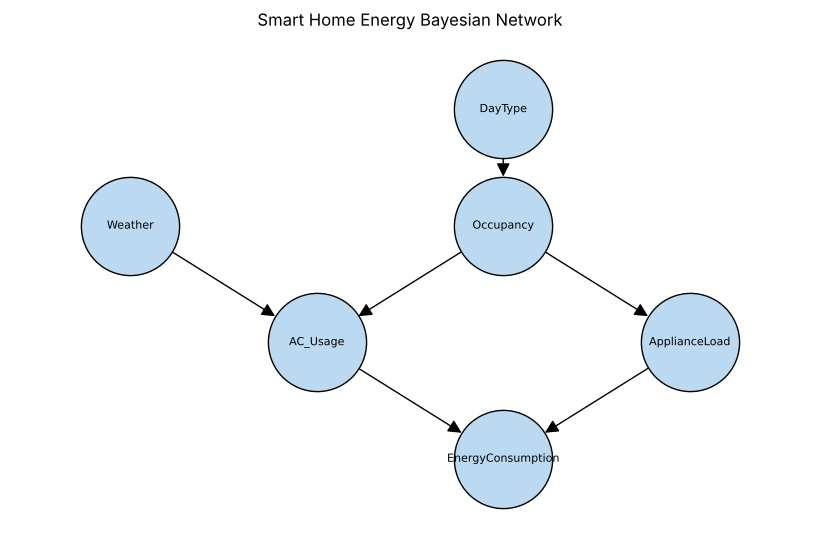

In [5]:
G = nx.DiGraph()
G.add_edges_from([(full_name[a], full_name[b]) for a, b in edges])

pos = {
    "Weather": (0, 2), "DayType": (2, 3),
    "Occupancy": (2, 2), "AC_Usage": (1, 1),
    "ApplianceLoad": (3, 1), "EnergyConsumption": (2, 0),
}

plt.figure(figsize=(8, 5))
nx.draw(G, pos, with_labels=True, node_size=5000, node_color="#bcd9f2",
        font_size=8, arrowsize=20, edgecolors="black")
plt.title("Smart Home Energy Bayesian Network")
plt.margins(0.15)
plt.show()

## 6. Inference queries Q1 - Q7

In [6]:
queries = [
    ("Q1", "E", "High", {}),
    ("Q2", "E", "High", {"W": "Hot"}),
    ("Q3", "E", "High", {"D": "Weekend"}),
    ("Q4", "E", "High", {"W": "Cold", "O": "High"}),
    ("Q5", "W", "Hot",  {"E": "High"}),
    ("Q6", "A", "On",   {"E": "High"}),
    ("Q7", "A", "On",   {"E": "High", "L": "Heavy"}),
]

def ask(model, var, value, evidence):
    infer = VariableElimination(model)
    result = infer.query([var], evidence=evidence if evidence else None, show_progress=False)
    return result.get_value(**{var: value})

def query_text(var, value, evidence):
    s = f"P({full_name[var]}={value}"
    if evidence:
        s += " | " + ", ".join(f"{full_name[k]}={v}" for k, v in evidence.items())
    return s + ")"

expert_answers = {}
for name, var, value, ev in queries:
    p = ask(expert, var, value, ev)
    expert_answers[name] = p
    print(f"{name}: {query_text(var, value, ev):<60} = {p:.4f}")

Q1: P(EnergyConsumption=High)                                    = 0.5806
Q2: P(EnergyConsumption=High | Weather=Hot)                      = 0.7063
Q3: P(EnergyConsumption=High | DayType=Weekend)                  = 0.6402
Q4: P(EnergyConsumption=High | Weather=Cold, Occupancy=High)     = 0.4843
Q5: P(Weather=Hot | EnergyConsumption=High)                      = 0.6082
Q6: P(AC_Usage=On | EnergyConsumption=High)                      = 0.6929
Q7: P(AC_Usage=On | EnergyConsumption=High, ApplianceLoad=Heavy) = 0.6499


## 7. Explaining away (Q6 vs Q7)

In [7]:
print(f"Q6  P(AC=On | E=High)              = {expert_answers['Q6']:.4f}")
print(f"Q7  P(AC=On | E=High, Load=Heavy)  = {expert_answers['Q7']:.4f}")
print(f"Change = {expert_answers['Q7'] - expert_answers['Q6']:+.4f}")
print()
print(f"Prior P(AC=On) = {ask(expert, 'A', 'On', {}):.4f}")
print(f"P(Load=Heavy)  = {ask(expert, 'L', 'Heavy', {}):.4f}   P(Load=Heavy | E=High) = {ask(expert, 'L', 'Heavy', {'E': 'High'}):.4f}")

Q6  P(AC=On | E=High)              = 0.6929
Q7  P(AC=On | E=High, Load=Heavy)  = 0.6499
Change = -0.0430

Prior P(AC=On) = 0.4854
P(Load=Heavy)  = 0.5720   P(Load=Heavy | E=High) = 0.7336


**Explanation.** AC usage and appliance load are both causes of high energy consumption, so `E` is a common effect (A → E ← L). Once we see E = High, the probability of AC = On jumps from its prior of about 0.49 to 0.69 because the AC is one of the likely reasons. When we are also told that the appliance load is Heavy, a lot of the high consumption is already accounted for by the appliances, so the AC is needed less as an explanation and P(AC = On) drops to 0.65. That drop is explaining away: two causes compete to explain the same effect, and confirming one makes the other less likely.

It does not drop all the way back to the prior because A and L are not independent to begin with. Both depend on Occupancy, so a heavy load also hints at high occupancy, which pushes AC usage up a little. The net effect is still a decrease.

## 8. Q1 by hand

Energy depends only on A and L, so

$$P(E{=}H) = \sum_{a,l} P(E{=}H \mid a,l)\,P(a,l), \qquad P(a,l) = \sum_{o} P(o)\,P(a\mid o)\,P(l\mid o)$$

and P(a | o) needs Weather summed out: P(a | o) = Σ_w P(w) P(a | w, o).

**Step 1: Occupancy**
P(O=High) = 0.7(0.45) + 0.3(0.80) = 0.315 + 0.240 = **0.555**, so P(O=Low) = **0.445**

**Step 2: AC given Occupancy (Weather summed out)**
P(A=On | O=High) = 0.5(0.90) + 0.3(0.40) + 0.2(0.10) = 0.45 + 0.12 + 0.02 = **0.590**
P(A=On | O=Low) = 0.5(0.60) + 0.3(0.15) + 0.2(0.05) = 0.30 + 0.045 + 0.01 = **0.355**

**Step 3: Joint of A and L**

| A, L | O=High term (0.555) | O=Low term (0.445) | P(A, L) |
|---|---|---|---|
| On, Heavy | 0.555 × 0.59 × 0.75 = 0.245588 | 0.445 × 0.355 × 0.35 = 0.055291 | 0.300879 |
| On, Light | 0.555 × 0.59 × 0.25 = 0.081863 | 0.445 × 0.355 × 0.65 = 0.102684 | 0.184546 |
| Off, Heavy | 0.555 × 0.41 × 0.75 = 0.170663 | 0.445 × 0.645 × 0.35 = 0.100459 | 0.271121 |
| Off, Light | 0.555 × 0.41 × 0.25 = 0.056888 | 0.445 × 0.645 × 0.65 = 0.186566 | 0.243454 |

(The four values add to 1.)

**Step 4: Energy**
P(E=High) = 0.92(0.300879) + 0.68(0.184546) + 0.55(0.271121) + 0.12(0.243454)
= 0.276808 + 0.125491 + 0.149117 + 0.029214 = **0.5806**

In [8]:
# same steps in code, to confirm the hand calculation
pD = {"Weekday": 0.7, "Weekend": 0.3}
pW = {"Hot": 0.5, "Mild": 0.3, "Cold": 0.2}
pO_high = {"Weekday": 0.45, "Weekend": 0.80}
pA_on = {("Hot", "High"): 0.90, ("Hot", "Low"): 0.60, ("Mild", "High"): 0.40,
         ("Mild", "Low"): 0.15, ("Cold", "High"): 0.10, ("Cold", "Low"): 0.05}
pL_heavy = {"High": 0.75, "Low": 0.35}
pE_high = {("On", "Heavy"): 0.92, ("On", "Light"): 0.68, ("Off", "Heavy"): 0.55, ("Off", "Light"): 0.12}

o_high = sum(pD[d] * pO_high[d] for d in pD)
pO = {"High": o_high, "Low": 1 - o_high}

total = 0
for a in ["On", "Off"]:
    for l in ["Heavy", "Light"]:
        p_al = 0
        for o in ["High", "Low"]:
            p_a = sum(pW[w] * pA_on[(w, o)] for w in pW)
            if a == "Off":
                p_a = 1 - p_a
            p_l = pL_heavy[o] if l == "Heavy" else 1 - pL_heavy[o]
            p_al += pO[o] * p_a * p_l
        total += pE_high[(a, l)] * p_al
        print(f"P(A={a}, L={l}) = {p_al:.6f}   contribution = {pE_high[(a, l)] * p_al:.6f}")

print(f"\nHand calculation : {total:.6f}")
print(f"pgmpy (Q1)       : {expert_answers['Q1']:.6f}")
print("Match:", abs(total - expert_answers['Q1']) < 1e-9)

P(A=On, L=Heavy) = 0.300879   contribution = 0.276808
P(A=On, L=Light) = 0.184546   contribution = 0.125491
P(A=Off, L=Heavy) = 0.271121   contribution = 0.149117
P(A=Off, L=Light) = 0.243454   contribution = 0.029214

Hand calculation : 0.580631
pgmpy (Q1)       : 0.580631
Match: True


# Part B - Conditional Independence

## 9. d-separation check

In [9]:
tests = [
    ("Weather ⊥ DayType",                       "W", "D", []),
    ("Weather ⊥ DayType | EnergyConsumption",   "W", "D", ["E"]),
    ("Weather ⊥ ApplianceLoad | Occupancy",     "W", "L", ["O"]),
]
for text, x, y, given in tests:
    connected = expert.is_dconnected(x, y, observed=given)
    print(f"{text:<42} d-separated: {not connected}")

Weather ⊥ DayType                          d-separated: True
Weather ⊥ DayType | EnergyConsumption      d-separated: False
Weather ⊥ ApplianceLoad | Occupancy        d-separated: True


**1. Weather ⊥ DayType: holds.** The only trail between them is W → A ← O ← D (and the longer W → A → E ← L ← O ← D). Both run through a collider (A, or E) and nothing is observed, so every trail is blocked.

**2. Weather ⊥ DayType | EnergyConsumption: does not hold.** E is a descendant of the collider A and is itself a collider on the second trail. Observing E opens both colliders, so W → A ← O ← D becomes active (O is not observed, so the chain part stays open). Knowing the energy was high and that it is a weekend tells us something about the weather.

**3. Weather ⊥ ApplianceLoad | Occupancy: holds.** Every trail from W to L has to reach L through O. On W → A ← O → L the collider A is unobserved (and so is its descendant E), so it is blocked already. On W → A → E ← L the collider E is unobserved, also blocked. Observing O additionally blocks the fork O → L. So W and L are d-separated.

## 10. Numerical verification

In [10]:
def max_gap(target, other, given):
    # compare P(target | given) with P(target | given, other) over every combination of values
    import itertools
    worst = 0
    given_vars = list(given)
    for g_vals in itertools.product(*[states[v] for v in given_vars]):
        ev = dict(zip(given_vars, g_vals))
        base = VariableElimination(expert).query([target], evidence=ev or None, show_progress=False)
        for o_val in states[other]:
            ev2 = dict(ev)
            ev2[other] = o_val
            cond = VariableElimination(expert).query([target], evidence=ev2, show_progress=False)
            for t_val in states[target]:
                gap = abs(base.get_value(**{target: t_val}) - cond.get_value(**{target: t_val}))
                worst = max(worst, gap)
    return worst

print("Statement 1")
print(f"  P(W=Hot)               = {ask(expert, 'W', 'Hot', {}):.4f}")
print(f"  P(W=Hot | D=Weekend)   = {ask(expert, 'W', 'Hot', {'D': 'Weekend'}):.4f}")
print(f"  largest gap over all values = {max_gap('W', 'D', []):.6f}")

print("Statement 2")
print(f"  P(W=Hot | E=High)              = {ask(expert, 'W', 'Hot', {'E': 'High'}):.4f}")
print(f"  P(W=Hot | E=High, D=Weekend)   = {ask(expert, 'W', 'Hot', {'E': 'High', 'D': 'Weekend'}):.4f}")
print(f"  P(W=Hot | E=High, D=Weekday)   = {ask(expert, 'W', 'Hot', {'E': 'High', 'D': 'Weekday'}):.4f}")
print(f"  largest gap over all values = {max_gap('W', 'D', ['E']):.6f}")

print("Statement 3")
print(f"  P(W=Hot | O=High)              = {ask(expert, 'W', 'Hot', {'O': 'High'}):.4f}")
print(f"  P(W=Hot | O=High, L=Heavy)     = {ask(expert, 'W', 'Hot', {'O': 'High', 'L': 'Heavy'}):.4f}")
print(f"  largest gap over all values = {max_gap('W', 'L', ['O']):.6f}")

Statement 1
  P(W=Hot)               = 0.5000
  P(W=Hot | D=Weekend)   = 0.5000
  largest gap over all values = 0.000000
Statement 2
  P(W=Hot | E=High)              = 0.6082
  P(W=Hot | E=High, D=Weekend)   = 0.5998
  P(W=Hot | E=High, D=Weekday)   = 0.6124
  largest gap over all values = 0.027699
Statement 3
  P(W=Hot | O=High)              = 0.5000
  P(W=Hot | O=High, L=Heavy)     = 0.5000
  largest gap over all values = 0.000000


The numbers agree with d-separation. For statements 1 and 3 the conditional probabilities are identical for every value combination (gap 0 up to floating point). For statement 2, adding DayType = Weekend moves P(Weather=Hot | E=High) from 0.6082 to 0.5998, and DayType = Weekday moves it up to 0.6124. On a weekend occupancy is more likely to be high, and that already explains part of the high consumption, so Hot weather is needed a bit less as an explanation.

# Part C - Synthetic Data Generation

## 11. Ancestral sampler

In [11]:
# the sampler reads its probabilities from these plain dicts, written straight from the tables in the PDF
topo_order = ["W", "D", "O", "A", "L", "E"]

def dist(var, row):
    # returns the probability of each state of var, in the order of states[var]
    if var == "W":
        return [0.5, 0.3, 0.2]
    if var == "D":
        return [0.7, 0.3]
    if var == "O":
        p = pO_high[row["D"]]
    elif var == "A":
        p = pA_on[(row["W"], row["O"])]
    elif var == "L":
        p = pL_heavy[row["O"]]
    elif var == "E":
        p = pE_high[(row["A"], row["L"])]
    return [p, 1 - p]

def ancestral_sample(n, seed):
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(n):
        row = {}
        for var in topo_order:            # parents are always filled in before children
            probs = dist(var, row)
            k = rng.choice(len(probs), p=probs)
            row[var] = states[var][k]
        rows.append(row)
    return pd.DataFrame(rows, columns=topo_order)

datasets = {}
for n in SIZES:
    datasets[n] = ancestral_sample(n, SEED)
    datasets[n].to_csv(f"smart_home_{n}.csv", index=False)

print("Random seed:", SEED)
datasets[500].head(10)

Random seed: 42


,W,D,O,A,L,E
0,Mild,Weekday,Low,Off,Heavy,Low
1,Mild,Weekend,High,Off,Heavy,Low
2,Mild,Weekend,High,On,Heavy,High
3,Cold,Weekday,Low,Off,Light,Low
4,Mild,Weekday,Low,On,Heavy,High
5,Mild,Weekend,High,On,Heavy,High
6,Hot,Weekday,High,On,Heavy,High
7,Mild,Weekday,Low,Off,Light,Low
8,Mild,Weekday,High,On,Light,High
9,Mild,Weekend,High,Off,Heavy,High


## 12. Weather frequencies and (Weather, Occupancy) counts

In [12]:
freq_rows = []
for n in SIZES:
    vc = datasets[n]["W"].value_counts(normalize=True)
    freq_rows.append([n] + [round(vc.get(s, 0), 4) for s in states["W"]])
freq = pd.DataFrame(freq_rows, columns=["Samples", "Hot", "Mild", "Cold"])
freq.loc[len(freq)] = ["True value", 0.5, 0.3, 0.2]
freq

,Samples,Hot,Mild,Cold
0,500,0.5100,0.2860,0.2040
1,5000,0.4992,0.3020,0.1988
2,20000,0.4953,0.3058,0.1989
3,True value,0.5000,0.3000,0.2000


In [13]:
for n in SIZES:
    ct = pd.crosstab(datasets[n]["W"], datasets[n]["O"]).reindex(index=states["W"], columns=states["O"])
    print(f"--- {n} samples ---")
    print(ct, "\n")

--- 500 samples ---
O     High  Low
W              
Hot    155  100
Mild    75   68
Cold    51   51 

--- 5000 samples ---
O     High   Low
W               
Hot   1402  1094
Mild   823   687
Cold   558   436 

--- 20000 samples ---
O     High   Low
W               
Hot   5520  4386
Mild  3416  2700
Cold  2228  1750 



# Part D - Learning from Data

## 13. Learning with MLE and BDeu

In [14]:
def learn(df, method):
    model = DiscreteBayesianNetwork(edges)
    if method == "mle":
        est = MaximumLikelihoodEstimator(model, df)
        cpds = [est.estimate_cpd(v) for v in topo_order]
    else:
        est = BayesianEstimator(model, df)
        cpds = [est.estimate_cpd(v, prior_type="BDeu", equivalent_sample_size=10) for v in topo_order]
    model.add_cpds(*cpds)
    assert model.check_model()
    return model

learned = {}
for n in SIZES:
    learned[(n, "mle")] = learn(datasets[n], "mle")
    learned[(n, "bayes")] = learn(datasets[n], "bayes")
print("Learned", len(learned), "networks")

Learned 6 networks


## 14. Learned AC Usage CPT vs expert CPT

In [15]:
def ac_table(n):
    rows = []
    for w in states["W"]:
        for o in states["O"]:
            r = {"Weather": w, "Occupancy": o, "Expert": pA_on[(w, o)]}
            for method, label in [("mle", "MLE"), ("bayes", "BDeu")]:
                cpd = learned[(n, method)].get_cpds("A")
                r[label] = cpd.get_value(A="On", W=w, O=o)
            r["Count"] = int(((datasets[n]["W"] == w) & (datasets[n]["O"] == o)).sum())
            rows.append(r)
    return pd.DataFrame(rows).round(4)

for n in SIZES:
    print(f"P(AC = On | Weather, Occupancy) with {n} samples")
    display(ac_table(n))

P(AC = On | Weather, Occupancy) with 500 samples


,Weather,Occupancy,Expert,MLE,BDeu,Count
0,Hot,High,0.90,0.8516,0.8479,155
1,Hot,Low,0.60,0.6600,0.6574,100
2,Mild,High,0.40,0.3600,0.3630,75
3,Mild,Low,0.15,0.1765,0.1842,68
4,Cold,High,0.10,0.0980,0.1108,51
5,Cold,Low,0.05,0.0196,0.0348,51


P(AC = On | Weather, Occupancy) with 5000 samples


,Weather,Occupancy,Expert,MLE,BDeu,Count
0,Hot,High,0.90,0.8937,0.8933,1402
1,Hot,Low,0.60,0.6188,0.6186,1094
2,Mild,High,0.40,0.3900,0.3903,823
3,Mild,Low,0.15,0.1514,0.1522,687
4,Cold,High,0.10,0.1039,0.1051,558
5,Cold,Low,0.05,0.0482,0.0499,436


P(AC = On | Weather, Occupancy) with 20000 samples


,Weather,Occupancy,Expert,MLE,BDeu,Count
0,Hot,High,0.90,0.9013,0.9011,5520
1,Hot,Low,0.60,0.6008,0.6007,4386
2,Mild,High,0.40,0.3970,0.3970,3416
3,Mild,Low,0.15,0.1478,0.1480,2700
4,Cold,High,0.10,0.1041,0.1044,2228
5,Cold,Low,0.05,0.0537,0.0541,1750


## 15. Q1 - Q7 on the learned networks

In [16]:
results = {}
for n in SIZES:
    rows = []
    for name, var, value, ev in queries:
        e = expert_answers[name]
        m = ask(learned[(n, "mle")], var, value, ev)
        b = ask(learned[(n, "bayes")], var, value, ev)
        rows.append([name, e, m, b, abs(e - m), abs(e - b)])
    results[n] = pd.DataFrame(rows, columns=["Query", "Expert Model", "MLE Model", "Bayesian Model",
                                             "|Diff| MLE", "|Diff| Bayesian"])
print("done")

done


# Part E - Comparative Analysis

## 16. Comparison tables

In [17]:
for n in SIZES:
    print(f"===== {n} samples =====")
    display(results[n].round(4))

===== 500 samples =====


,Query,Expert Model,MLE Model,Bayesian Model,|Diff| MLE,|Diff| Bayesian
0,Q1,0.5806,0.5570,0.5559,0.0237,0.0247
1,Q2,0.7063,0.7050,0.6991,0.0013,0.0072
2,Q3,0.6402,0.6092,0.6046,0.0310,0.0356
3,Q4,0.4843,0.4203,0.4268,0.0639,0.0575
4,Q5,0.6082,0.6455,0.6370,0.0373,0.0288
5,Q6,0.6929,0.7280,0.7236,0.0351,0.0307
6,Q7,0.6499,0.6584,0.6560,0.0085,0.0061


===== 5000 samples =====


,Query,Expert Model,MLE Model,Bayesian Model,|Diff| MLE,|Diff| Bayesian
0,Q1,0.5806,0.5794,0.5793,0.0012,0.0014
1,Q2,0.7063,0.7034,0.7028,0.0029,0.0035
2,Q3,0.6402,0.6399,0.6393,0.0003,0.0009
3,Q4,0.4843,0.4860,0.4863,0.0017,0.0021
4,Q5,0.6082,0.6060,0.6053,0.0022,0.0029
5,Q6,0.6929,0.6884,0.6881,0.0044,0.0048
6,Q7,0.6499,0.6496,0.6493,0.0003,0.0006


===== 20000 samples =====


,Query,Expert Model,MLE Model,Bayesian Model,|Diff| MLE,|Diff| Bayesian
0,Q1,0.5806,0.5768,0.5768,0.0038,0.0038
1,Q2,0.7063,0.7028,0.7026,0.0035,0.0036
2,Q3,0.6402,0.6381,0.6379,0.0021,0.0023
3,Q4,0.4843,0.4838,0.4839,0.0004,0.0004
4,Q5,0.6082,0.6035,0.6033,0.0047,0.0049
5,Q6,0.6929,0.6922,0.6921,0.0007,0.0008
6,Q7,0.6499,0.6499,0.6499,0.0001,0.0000


## 17. Mean absolute difference vs dataset size

,Samples,Mean |Diff| MLE,Mean |Diff| Bayesian
0,500,0.02868,0.02722
1,5000,0.00187,0.00230
2,20000,0.00219,0.00226


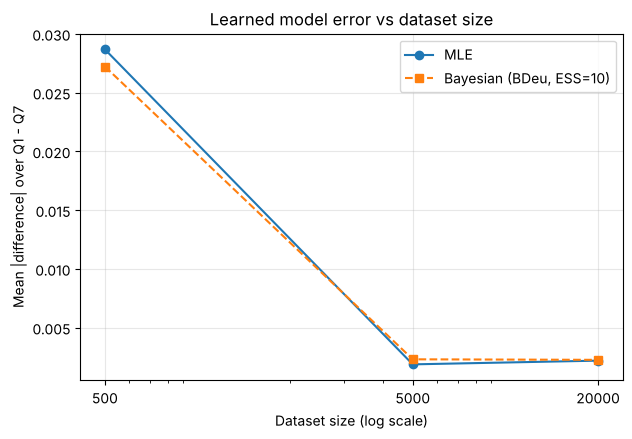

In [18]:
mean_mle = [results[n]["|Diff| MLE"].mean() for n in SIZES]
mean_bay = [results[n]["|Diff| Bayesian"].mean() for n in SIZES]
summary = pd.DataFrame({"Samples": SIZES, "Mean |Diff| MLE": mean_mle, "Mean |Diff| Bayesian": mean_bay})
display(summary.round(5))

plt.figure(figsize=(7, 4.5))
plt.plot(SIZES, mean_mle, "o-", label="MLE")
plt.plot(SIZES, mean_bay, "s--", label="Bayesian (BDeu, ESS=10)")
plt.xscale("log")
plt.xticks(SIZES, [str(s) for s in SIZES])
plt.xlabel("Dataset size (log scale)")
plt.ylabel("Mean |difference| over Q1 - Q7")
plt.title("Learned model error vs dataset size")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 18. Which query is worst at 500 samples

In [19]:
r500 = results[500].copy()
r500["Worst of the two"] = r500[["|Diff| MLE", "|Diff| Bayesian"]].max(axis=1)
worst = r500.sort_values("Worst of the two", ascending=False).iloc[0]
print("Largest error at 500 samples:", worst["Query"])
print(r500[["Query", "|Diff| MLE", "|Diff| Bayesian"]].round(4).to_string(index=False))

df500 = datasets[500]
print()
print("How often the evidence of each query shows up in the 500-sample data:")
for name, var, value, ev in queries:
    mask = pd.Series(True, index=df500.index)
    for k, v in ev.items():
        mask &= df500[k] == v
    print(f"  {name}: {ev if ev else 'no evidence'} -> {mask.sum()} rows")

Largest error at 500 samples: Q4
Query  |Diff| MLE  |Diff| Bayesian
   Q1      0.0237           0.0247
   Q2      0.0013           0.0072
   Q3      0.0310           0.0356
   Q4      0.0639           0.0575
   Q5      0.0373           0.0288
   Q6      0.0351           0.0307
   Q7      0.0085           0.0061

How often the evidence of each query shows up in the 500-sample data:
  Q1: no evidence -> 500 rows
  Q2: {'W': 'Hot'} -> 255 rows
  Q3: {'D': 'Weekend'} -> 157 rows
  Q4: {'W': 'Cold', 'O': 'High'} -> 51 rows
  Q5: {'E': 'High'} -> 280 rows
  Q6: {'E': 'High'} -> 280 rows
  Q7: {'E': 'High', 'L': 'Heavy'} -> 198 rows


## 19. Analysis

**Comparison across sizes.** With 500 samples the learned models are noticeably off, with a mean absolute difference of 0.0287 for MLE and 0.0272 for BDeu. At 5000 samples both drop by more than ten times, to 0.0019 (MLE) and 0.0023 (BDeu). At 20000 samples the means are 0.0022 and 0.0023, so they did not keep falling. That is sampling noise from a single seeded dataset: the 20000 sample happens to have slightly fewer Hot days (0.4953 instead of 0.5), which pulls Q1, Q2 and Q5 off by about 0.004. Once the error is down at the 0.002 level, one random draw can be a bit luckier than a bigger one. The learned AC CPT shows the same trend, every entry is within 0.004 of the expert value at 20000 samples, while at 500 the Cold/Low entry came out as 0.0196 instead of 0.05.

**Largest error at 500 samples: Q4.** Q4 is P(E=High | Weather=Cold, Occupancy=High), and its error was 0.0639 for MLE and 0.0575 for BDeu, the worst of all seven. Its evidence is the rarest: only 51 of the 500 rows have Cold weather with High occupancy, compared with 157 to 500 rows for the evidence of the other queries. On cold days the AC is almost always off, so the answer also leans on the "AC = Off" columns of the Energy CPT, which were themselves estimated badly (P(E=High | Off, Light) came out as 0.060 instead of 0.12), and on P(Heavy | O=High), which came out as 0.698 instead of 0.75. All three errors push the answer down in the same direction, so they add up instead of cancelling.

**Which estimator is better for small data.** In my runs BDeu was better at 500 samples (0.0272 vs 0.0287), and it was clearly better on the queries whose evidence is rare or whose CPT entries are close to 0, such as Q4 and Q5, and the Cold/Low AC entry (0.0348 vs MLE's 0.0196, with the true value at 0.05). MLE only uses counts, so a cell seen a few times can produce extreme estimates, and a cell never seen would get 0 or be undefined. BDeu adds an equivalent sample size of 10 spread uniformly as pseudo-counts over each CPT, which pulls estimates towards the middle and smooths out the noise. The cost is a small bias: at 5000 and 20000 samples MLE is slightly ahead because the prior is now pulling good estimates towards 0.5 for no reason. So the gap between the two is small, but for small datasets the Bayesian estimator is the safer choice, and with lots of data the choice stops mattering.